<a href="https://colab.research.google.com/github/c-o-n-n-o-r-1/IS-4487/blob/main/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

print(df.head())
print(df.describe())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The dataset loaded with 9,404 records. I noticed some unusual numbers, like a booking made 737 days in advance, one with 55 adults, and even a negative room price. I also noticed that some columns, like company, had a lot of missing information.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [ ]:
features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr']
df_subset = df[features].copy()

df_subset = df_subset.dropna().drop_duplicates()
df_subset = df_subset[(df_subset['adr'] > 0) & (df_subset['adr'] < 1000)]
df_subset = df_subset[df_subset['lead_time'] < 500]

scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_subset), columns=features)

### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. Selected features: I chose lead_time, stays_in_weekend_nights, stays_in_week_nights, and adr because they show how early someone books, how long they stay, and how much they spend per night.

2. Expected patterns: I think we might see groups like people who book last minute and stay for a short time, compared to people who plan ahead, stay longer, and spend more.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

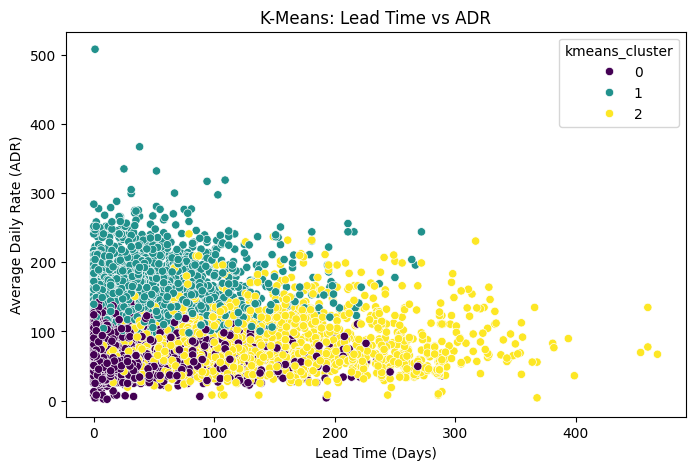

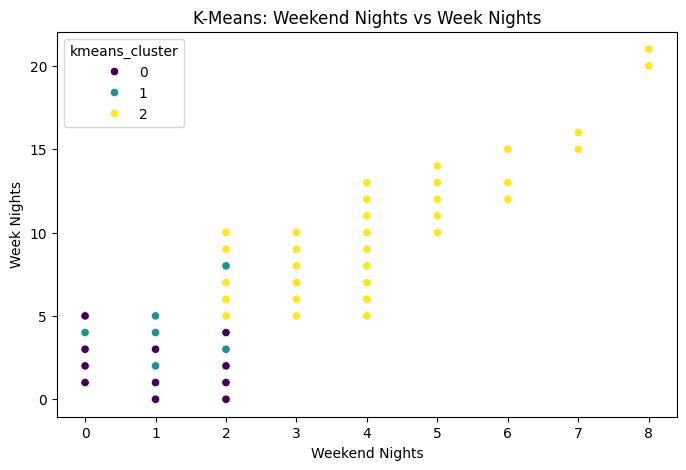

                 lead_time  stays_in_weekend_nights  stays_in_week_nights  \
kmeans_cluster                                                              
0                29.579877                 0.623656              1.809908   
1                53.689136                 1.270752              3.430641   
2               136.358217                 2.364125              5.839957   

                       adr  
kmeans_cluster              
0                65.025027  
1               164.071916  
2                85.114356  


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df_subset['kmeans_cluster'] = kmeans.fit_predict(df_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_subset, x='lead_time', y='adr', hue='kmeans_cluster', palette='viridis')
plt.title('K-Means: Lead Time vs ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_subset, x='stays_in_weekend_nights', y='stays_in_week_nights', hue='kmeans_cluster', palette='viridis')
plt.title('K-Means: Weekend Nights vs Week Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Week Nights')
plt.show()

kmeans_summary = df_subset.groupby('kmeans_cluster')[features].mean()
print(kmeans_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
I chose k = 3 because I thought having three customer groups would make it easier for the marketing manager to understand the different types of guests.

Cluster 0: These guests tend to book last minute and stay for a shorter amount of time.

Cluster 1: These guests usually stay longer, including both weekdays and weekends.

Cluster 2: These guests tend to book further in advance and spend more per night.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

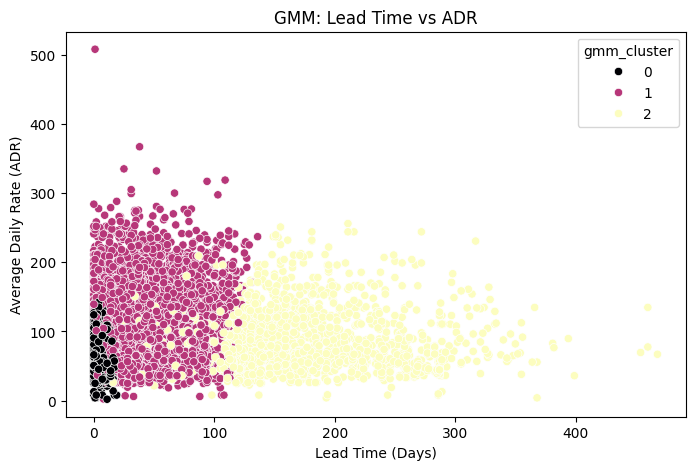

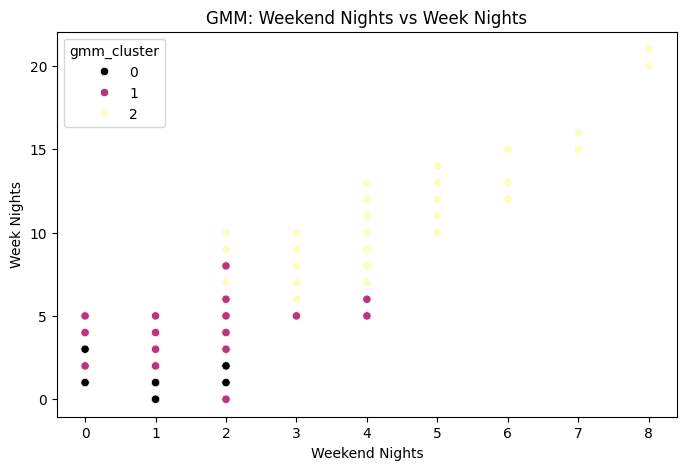

              lead_time  stays_in_weekend_nights  stays_in_week_nights  \
gmm_cluster                                                              
0              4.675933                 0.536211              1.258961   
1             49.355892                 1.280202              3.437815   
2            166.967213                 2.138361              5.535738   

                    adr  
gmm_cluster              
0             61.673906  
1            119.177480  
2             89.508216  


In [ ]:
gmm = GaussianMixture(n_components=3, random_state=42)
df_subset['gmm_cluster'] = gmm.fit_predict(df_scaled)
gmm_probs = gmm.predict_proba(df_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_subset, x='lead_time', y='adr', hue='gmm_cluster', palette='magma')
plt.title('GMM: Lead Time vs ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_subset, x='stays_in_weekend_nights', y='stays_in_week_nights', hue='gmm_cluster', palette='magma')
plt.title('GMM: Weekend Nights vs Week Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Week Nights')
plt.show()

gmm_summary = df_subset.groupby('gmm_cluster')[features].mean()
print(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM allowed customers to fit into more than one group based on probability, while K-Means placed each customer into just one group.
2. GMM could help businesses understand customers who have traits from different groups. This could make it easier to create promotions that appeal to more than one type of guest.

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [ ]:
df_combined = pd.DataFrame(df_scaled, columns=features)
df_combined['kmeans_cluster'] = df_subset['kmeans_cluster'].values
df_combined['gmm_cluster'] = df_subset['gmm_cluster'].values

sample_df = df_combined.sample(n=min(10000, len(df_combined)), random_state=42)

sample_features = sample_df[features]
sample_kmeans_labels = sample_df['kmeans_cluster']
sample_gmm_labels = sample_df['gmm_cluster']

wcss_kmeans = kmeans.inertia_

sil_kmeans = silhouette_score(sample_features, sample_kmeans_labels)
db_kmeans = davies_bouldin_score(sample_features, sample_kmeans_labels)

sil_gmm = silhouette_score(sample_features, sample_gmm_labels)
db_gmm = davies_bouldin_score(sample_features, sample_gmm_labels)

print(f"K-Means -> WCSS: {wcss_kmeans:.2f}, Silhouette Score: {sil_kmeans:.4f}, Davies-Bouldin Index: {db_kmeans:.4f}")
print(f"GMM     -> Silhouette Score: {sil_gmm:.4f}, Davies-Bouldin Index: {db_gmm:.4f}")

K-Means -> WCSS: 13263.08, Silhouette Score: 0.2940, Davies-Bouldin Index: 1.2329
GMM     -> Silhouette Score: 0.1592, Davies-Bouldin Index: 1.5436


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better because it had a higher Silhouette score (0.2940 vs. 0.1592) and a lower Davies-Bouldin score (1.2329 vs. 1.5436). This shows that the groups were more clearly separated.

5.3. I would recommend K-Means because the groups are easier to understand and explain. I think it would be more useful for a business analyst who needs to share the results with others.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [ ]:
cluster_interpretation = df_subset.groupby('kmeans_cluster')[features].mean().sort_values(by='adr', ascending=False)
print(cluster_interpretation)

                 lead_time  stays_in_weekend_nights  stays_in_week_nights  \
kmeans_cluster                                                              
1                53.689136                 1.270752              3.430641   
2               136.358217                 2.364125              5.839957   
0                29.579877                 0.623656              1.809908   

                       adr  
kmeans_cluster              
1               164.071916  
2                85.114356  
0                65.025027  


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The groups show different types of guests and their booking habits. Cluster 1 spends more per night, Cluster 2 plans ahead and stays longer, and Cluster 0 books closer to their trip and spends less.

2. I think the hotel could offer nicer rooms or upgrades to Cluster 1, discounts for booking early or staying longer to Cluster 2, and last-minute deals to Cluster 0.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part for me was figuring out how to scale the data and understand what each group meant since there wasn't really a correct answer to compare it to.

2. I would use clustering when I want to find patterns in data without already knowing the groups. I would use supervised models when I have past data to help predict something.

3. I would explain that clustering helps us group customers based on their habits. This can help the hotel better understand its guests and offer promotions that fit each group.

4. I think this project helped me better understand how machine learning can be used with real data to find patterns and help businesses make decisions.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_09_clustering.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
